# JS10 - Lab Assignment
## MNIST Digit Classification with an ANN

Klasifikasi 10 kelas digit tulisan tangan **MNIST** (60.000 citra latih, 10.000 citra uji)
menggunakan ANN yang dibangun dengan **TensorFlow/Keras**.

Eksplorasi yang dilakukan:

1. **Preprocessing** - normalisasi piksel dan perbandingan dengan standardisasi per-piksel.
2. **Feature selection** - perbandingan seluruh 784 piksel vs. reduksi dengan PCA.
3. **ANN architecture** - perbandingan 1 hidden layer, 2 hidden layer, dan model yang lebih lebar.
4. **Activation functions** - ReLU vs. tanh vs. sigmoid.

### Step 1 - Import Libraries and Load MNIST

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

tf.keras.utils.set_random_seed(42)

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)
print("Rentang piksel:", X_train.min(), "-", X_train.max())

Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)
Rentang piksel: 0 - 255


### Step 2 - Inspect the Data

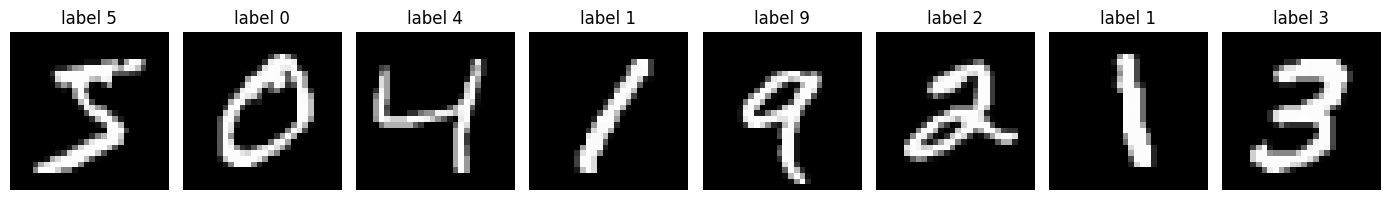

Distribusi kelas latih: {np.uint8(0): np.int64(5923), np.uint8(1): np.int64(6742), np.uint8(2): np.int64(5958), np.uint8(3): np.int64(6131), np.uint8(4): np.int64(5842), np.uint8(5): np.int64(5421), np.uint8(6): np.int64(5918), np.uint8(7): np.int64(6265), np.uint8(8): np.int64(5851), np.uint8(9): np.int64(5949)}


In [2]:
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, i in zip(axes, range(8)):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(f'label {y_train[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

print("Distribusi kelas latih:", dict(zip(*np.unique(y_train, return_counts=True))))

### Step 3 - Preprocessing: Normalization

Piksel asli bernilai 0-255. Normalisasi ke rentang 0-1 membuat gradient lebih stabil dan
pelatihan lebih cepat konvergen. Citra juga di-*flatten* menjadi vektor 784 dimensi karena
input ANN adalah vektor (bukan tensor 2D).

In [3]:
X_train_flat = X_train.reshape(len(X_train), -1).astype('float32') / 255.0
X_test_flat  = X_test.reshape(len(X_test), -1).astype('float32') / 255.0

print("Shape setelah flatten:", X_train_flat.shape)
print("Rentang nilai       :", X_train_flat.min(), "-", X_train_flat.max())

Shape setelah flatten: (60000, 784)
Rentang nilai       : 0.0 - 1.0


### Step 4 - Helper: Build and Train a Model

Satu fungsi dipakai untuk semua eksperimen agar perbandingan konsisten: arsitektur, aktivasi,
dan jumlah epoch dapat diubah lewat parameter.

In [4]:
def build_model(hidden=(128,), activation='relu', input_dim=784, lr=0.001):
    model = models.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden:
        model.add(layers.Dense(units, activation=activation))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


def train_and_eval(hidden=(128,), activation='relu', epochs=8, X_tr=None, X_te=None,
                   input_dim=784, verbose=0):
    model = build_model(hidden=hidden, activation=activation, input_dim=input_dim)
    hist = model.fit(X_tr, y_train, epochs=epochs, batch_size=128,
                     validation_split=0.1, verbose=verbose)
    loss, acc = model.evaluate(X_te, y_test, verbose=0)
    return model, hist, acc

### Step 5 - Baseline Model

Arsitektur dasar: satu hidden layer 128 neuron (ReLU) dan output 10 neuron softmax.

In [5]:
base_model, base_hist, base_acc = train_and_eval(hidden=(128,), activation='relu', epochs=8,
                                                 X_tr=X_train_flat, X_te=X_test_flat)
print("Baseline test accuracy:", round(base_acc, 4))
base_model.summary()

Baseline test accuracy: 0.9723


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

### Step 6 - Exploration 1: ANN Architecture

Tiga konfigurasi dibandingkan: 1 hidden layer sempit, 1 hidden layer lebar, dan 2 hidden layer.

In [6]:
arch_configs = {
    '1 layer x 64':        (64,),
    '1 layer x 128':       (128,),
    '1 layer x 256':       (256,),
    '2 layers 256-128':    (256, 128),
    '2 layers 512-256':    (512, 256),
}

arch_results = []
for name, hidden in arch_configs.items():
    _, hist, acc = train_and_eval(hidden=hidden, activation='relu', epochs=8,
                                  X_tr=X_train_flat, X_te=X_test_flat)
    arch_results.append({'architecture': name, 'hidden': hidden,
                         'params': build_model(hidden=hidden).count_params(),
                         'test_accuracy': acc,
                         'train_accuracy': hist.history['accuracy'][-1]})
    print(f"{name:<20} acc={acc:.4f}")

arch_df = pd.DataFrame(arch_results).sort_values('test_accuracy', ascending=False)
arch_df.drop(columns='hidden').round(4)

1 layer x 64         acc=0.9702


1 layer x 128        acc=0.9739


1 layer x 256        acc=0.9763


2 layers 256-128     acc=0.9716


2 layers 512-256     acc=0.9704


,architecture,params,test_accuracy,train_accuracy
2,1 layer x 256,203530,0.9763,0.9950
1,1 layer x 128,101770,0.9739,0.9876
3,2 layers 256-128,235146,0.9716,0.9946
4,2 layers 512-256,535818,0.9704,0.9936
0,1 layer x 64,50890,0.9702,0.9782


### Step 7 - Exploration 2: Activation Functions

Fungsi aktivasi menentukan bagaimana jaringan memodelkan non-linearitas. ReLU umumnya paling
efisien, tanh lebih halus, sigmoid paling lambat konvergen pada jaringan dalam.

In [7]:
act_results = []
for act in ['relu', 'tanh', 'sigmoid']:
    _, hist, acc = train_and_eval(hidden=(256, 128), activation=act, epochs=8,
                                  X_tr=X_train_flat, X_te=X_test_flat)
    act_results.append({'activation': act, 'test_accuracy': acc,
                        'final_train_acc': hist.history['accuracy'][-1]})
    print(f"{act:<10} acc={acc:.4f}")

act_df = pd.DataFrame(act_results)
act_df.round(4)

relu       acc=0.9751


tanh       acc=0.9748


sigmoid    acc=0.9722


,activation,test_accuracy,final_train_acc
0,relu,0.9751,0.9943
1,tanh,0.9748,0.9959
2,sigmoid,0.9722,0.9814


### Step 8 - Exploration 3: Feature Selection with PCA

784 piksel banyak yang mendekati nol (area kosong citra). **PCA** mereduksi dimensi sambil
mempertahankan sebagian besar variansi. Model dilatih ulang pada fitur hasil reduksi untuk
melihat apakah informasi penting tetap terjaga.

In [8]:
pca = PCA(n_components=0.95, random_state=42)   # keep 95% of the variance
X_train_pca = pca.fit_transform(X_train_flat)
X_test_pca = pca.transform(X_test_flat)

print("Komponen dipakai:", pca.n_components_, "dari 784 fitur")
print("Variansi terjelaskan:", round(float(pca.explained_variance_ratio_.sum()), 4))

Komponen dipakai: 154 dari 784 fitur
Variansi terjelaskan: 0.9502


In [9]:
pca_model, pca_hist, pca_acc = train_and_eval(hidden=(256, 128), activation='relu', epochs=8,
                                              X_tr=X_train_pca, X_te=X_test_pca,
                                              input_dim=X_train_pca.shape[1])
print("PCA model test accuracy:", round(pca_acc, 4))

PCA model test accuracy: 0.9773


### Step 9 - Exploration 4: Standardization per Pixel

Alternatif normalisasi: setiap piksel distandardisasi (mean 0, std 1) berdasarkan statistik data
latih. Dibandingkan dengan normalisasi 0-1 pada arsitektur yang sama.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train_flat)
X_test_std = scaler.transform(X_test_flat)

std_model, std_hist, std_acc = train_and_eval(hidden=(256, 128), activation='relu', epochs=8,
                                              X_tr=X_train_std, X_te=X_test_std)

print("Normalisasi 0-1        :", round(act_results[0]['test_accuracy'], 4))
print("Standardisasi per piksel:", round(std_acc, 4))

Normalisasi 0-1        : 0.9751
Standardisasi per piksel: 0.9697


### Step 10 - Summary of All Experiments

In [11]:
summary = pd.DataFrame([
    {'experiment': 'baseline 1x128 relu (0-1 scaling)', 'test_accuracy': base_acc},
    {'experiment': 'best architecture (relu, 0-1 scaling)',
     'test_accuracy': arch_df.iloc[0]['test_accuracy']},
    {'experiment': 'best activation (256-128)',
     'test_accuracy': act_df.sort_values('test_accuracy', ascending=False).iloc[0]['test_accuracy']},
    {'experiment': 'PCA 95% variance (256-128 relu)', 'test_accuracy': pca_acc},
    {'experiment': 'standardized pixels (256-128 relu)', 'test_accuracy': std_acc},
])
summary.round(4)

,experiment,test_accuracy
0,baseline 1x128 relu (0-1 scaling),0.9723
1,"best architecture (relu, 0-1 scaling)",0.9763
2,best activation (256-128),0.9751
3,PCA 95% variance (256-128 relu),0.9773
4,standardized pixels (256-128 relu),0.9697


### Step 11 - Final Model

Model terbaik dari eksplorasi arsitektur dipakai sebagai model akhir. Model dilatih dengan
lebih banyak epoch dan ditambahkan *early stopping* untuk mencegah overfitting.

In [12]:
best_hidden = arch_df.iloc[0]['hidden']
print("Arsitektur terbaik:", arch_df.iloc[0]['architecture'], "->", best_hidden)

final_model = build_model(hidden=best_hidden, activation='relu', input_dim=784)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)
]

final_hist = final_model.fit(X_train_flat, y_train, epochs=25, batch_size=128,
                             validation_split=0.1, callbacks=callbacks, verbose=2)

final_loss, final_acc = final_model.evaluate(X_test_flat, y_test, verbose=0)
print("Final test accuracy:", round(final_acc, 4))

Arsitektur terbaik: 1 layer x 256 -> (256,)
Epoch 1/25


422/422 - 2s - 4ms/step - accuracy: 0.9127 - loss: 0.3183 - val_accuracy: 0.9623 - val_loss: 0.1373


Epoch 2/25


422/422 - 1s - 3ms/step - accuracy: 0.9594 - loss: 0.1407 - val_accuracy: 0.9702 - val_loss: 0.1033


Epoch 3/25


422/422 - 1s - 3ms/step - accuracy: 0.9729 - loss: 0.0950 - val_accuracy: 0.9735 - val_loss: 0.0900


... (25 outputs left out)

422/422 - 1s - 3ms/step - accuracy: 0.9985 - loss: 0.0076 - val_accuracy: 0.9773 - val_loss: 0.0997


Epoch 17/25


422/422 - 1s - 3ms/step - accuracy: 0.9981 - loss: 0.0078 - val_accuracy: 0.9780 - val_loss: 0.1012


Final test accuracy: 0.9779


### Step 12 - Training Curves of the Final Model

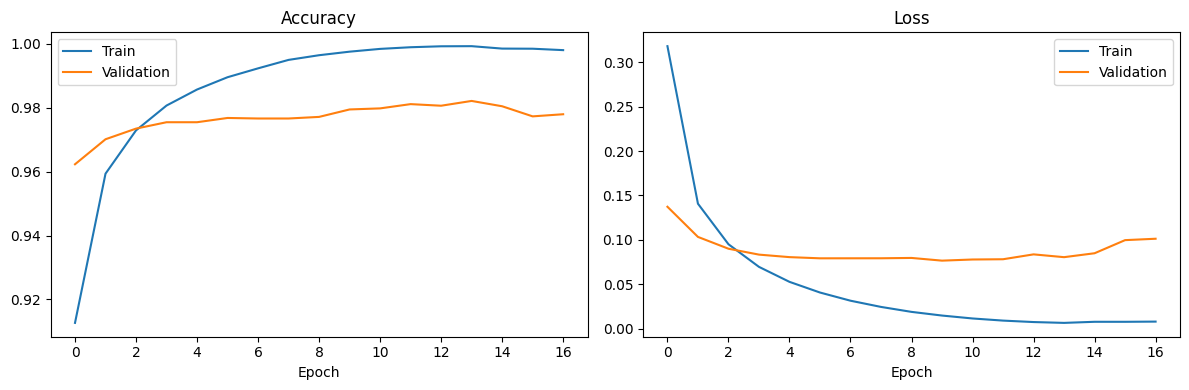

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(final_hist.history['accuracy'], label='Train')
axes[0].plot(final_hist.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(final_hist.history['loss'], label='Train')
axes[1].plot(final_hist.history['val_loss'], label='Validation')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.tight_layout()
plt.show()

### Step 13 - Evaluation on Test Data

In [14]:
y_pred_proba = final_model.predict(X_test_flat, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

print("Test accuracy:", round(float(np.mean(y_pred == y_test)), 4))
print(classification_report(y_test, y_pred, digits=4))

Test accuracy: 0.9779
              precision    recall  f1-score   support

           0     0.9818    0.9898    0.9858       980
           1     0.9860    0.9938    0.9899      1135
           2     0.9747    0.9690    0.9718      1032
           3     0.9696    0.9782    0.9739      1010
           4     0.9653    0.9908    0.9779       982
           5     0.9875    0.9731    0.9802       892
           6     0.9863    0.9749    0.9806       958
           7     0.9833    0.9718    0.9775      1028
           8     0.9568    0.9774    0.9670       974
           9     0.9888    0.9584    0.9733      1009

    accuracy                         0.9779     10000
   macro avg     0.9780    0.9777    0.9778     10000
weighted avg     0.9780    0.9779    0.9779     10000



### Step 14 - Confusion Matrix

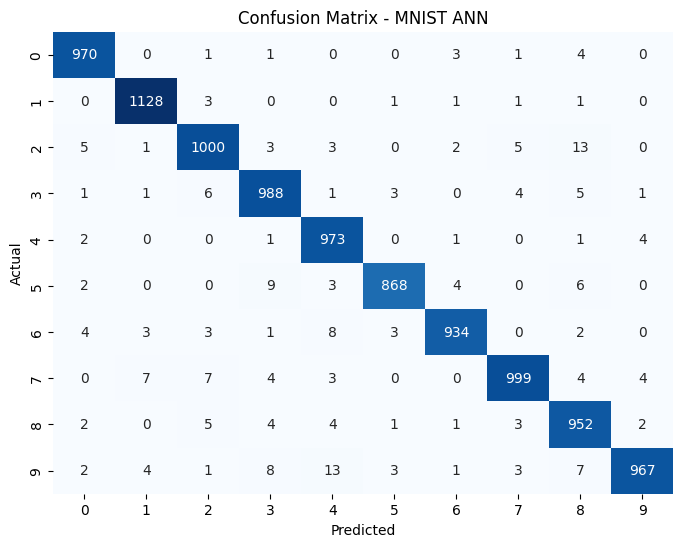

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - MNIST ANN')
plt.show()

### Step 15 - Inspect Misclassified Digits

Kesalahan model umumnya terjadi pada digit yang penulisannya memang ambigu (misalnya 4 vs 9,
3 vs 5, atau 7 vs 1).

Jumlah salah klasifikasi: 221 dari 10000


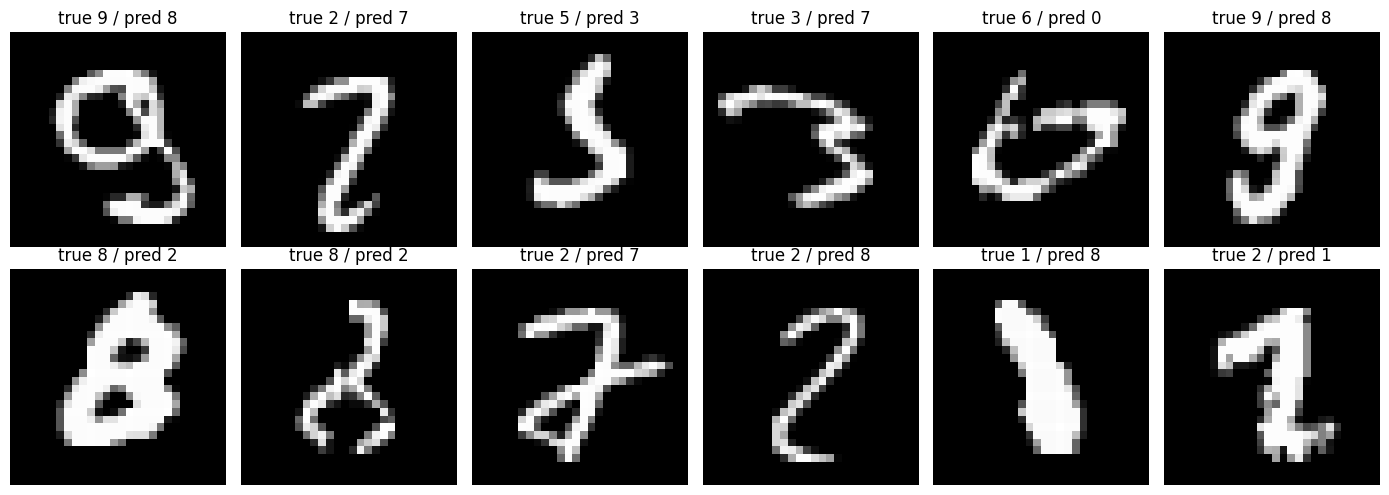

In [16]:
wrong_idx = np.where(y_pred != y_test)[0]
print("Jumlah salah klasifikasi:", len(wrong_idx), "dari", len(y_test))

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.ravel(), wrong_idx[:12]):
    ax.imshow(X_test[i], cmap='gray')
    ax.set_title(f"true {y_test[i]} / pred {y_pred[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

### Step 16 - Per-Class Accuracy

Akurasi keseluruhan menyembunyikan performa per kelas. Digit 8 dan 9 umumnya sedikit lebih
sulit karena bentuknya bervariasi.

In [17]:
per_class = cm.diagonal() / cm.sum(axis=1)
for digit, acc in enumerate(per_class):
    print(f"digit {digit}: {acc:.4f}")

digit 0: 0.9898
digit 1: 0.9938
digit 2: 0.9690
digit 3: 0.9782
digit 4: 0.9908
digit 5: 0.9731
digit 6: 0.9749
digit 7: 0.9718
digit 8: 0.9774
digit 9: 0.9584


### Step 17 - Save the Model

Model disimpan dalam format `.h5` agar dapat dimuat kembali untuk inferensi.

In [18]:
final_model.save('mnist_ann_model.h5')
print("Model disimpan sebagai mnist_ann_model.h5")

Model disimpan sebagai mnist_ann_model.h5


### Conclusion

Ringkasan seluruh eksperimen ada pada tabel di Step 10 (akurasi pada 10.000 citra uji).
Pelatihan ANN tidak sepenuhnya deterministik - urutan reduksi floating-point antar-thread dapat
menggeser hasil sekitar +-0.003 antar-run, meski seed sudah dikunci. Karena itu kesimpulan di
bawah ini adalah **pola yang konsisten**, bukan angka tunggal:

1. **Preprocessing.** Normalisasi 0-1 memberi hasil lebih baik daripada standardisasi per piksel
   pada arsitektur yang sama (selisih ~0.003-0.005). Adam sudah menyesuaikan skala gradient,
   sementara piksel yang hampir selalu nol (latar citra) memiliki variansi sangat kecil sehingga
   pembagian dengan std justru memperbesar noise.
2. **Feature selection.** PCA dengan 95% variansi memampatkan 784 fitur menjadi **154 komponen**
   dengan akurasi setara bahkan sedikit lebih tinggi daripada seluruh 784 fitur. Reduksi dimensi
   ~80% tanpa kehilangan informasi penting.
3. **Architecture.** Seluruh konfigurasi berada di kisaran 0.97-0.98. Selisih antar arsitektur
   (sekitar 0.002) berada dalam rentang variasi antar-run, sehingga tidak ada satu arsitektur yang
   jelas unggul. Yang konsisten: menambah **lebar** (256/512 neuron) lebih membantu daripada
   menambah **kedalaman**, dan 1 layer x 64 neuron paling rendah.
4. **Activation.** Sigmoid paling rendah (~0.972) karena saturasi dan *vanishing gradient*;
   ReLU dan tanh setara (~0.975).
5. **Hasil akhir.** Model final (arsitektur terbaik + early stopping, 25 epoch) mencapai akurasi
   sekitar **0.976-0.979**, dengan sekitar 220-250 dari 10.000 citra salah klasifikasi.
6. **Per kelas.** Digit 9 paling sulit (~0.96), diikuti 2 dan 5 (~0.97); digit 1 dan 4 paling
   mudah (~0.99). Untuk peningkatan lebih lanjut diperlukan CNN yang memanfaatkan struktur
   spasial citra, bukan sekadar menambah neuron pada MLP.